# CNN Architectures, Training and Ablation

Deep Learning Assignment 02

I trained AlexNet, VGG16, GoogLeNet and ResNet18 on CIFAR-10 using the same split and five epochs for each model. I then used a smaller CNN to test what changes when I add batch normalisation, augmentation and residual shortcuts. I also trained a classifier on a frozen ResNet50 and tested what happens when I fine tune its last block.

I used seed 42 for the main runs and seed 123 to repeat the five scratch ablations. I chose the model using validation results, then tested that checkpoint once on the original test set.

In [ ]:
from pathlib import Path
import os
import subprocess
import sys

work = Path.cwd()
if work.name != 'cnn_assignment_work':
    work = work / 'cnn_assignment_work'
work.mkdir(exist_ok=True)
os.chdir(work)
Path('src').mkdir(exist_ok=True)
Path('src/__init__.py').touch()
os.environ['DL2_SOURCE_COMMIT'] = '1701bec8baa3bb49ec55a09cb340b9dff8f960c2'
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

def run_module(module, *args):
    return subprocess.run([sys.executable, '-u', '-m', module, *map(str,args)], check=True)

def gpu_info():
    try:
        return subprocess.run(['nvidia-smi'], check=True, capture_output=True, text=True).stdout
    except (OSError, subprocess.CalledProcessError):
        return 'No NVIDIA runtime detected.'

print(gpu_info())

Sat Nov 21 14:29:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Numerical reasoning

In [2]:
%%writefile src/reasoning.py
"""Reproduce the hand calculations without a training dependency."""
from math import ceil, prod
import json


def trace():
    conv1 = (ceil(96/2), ceil(96/2), 32)
    q1 = {
        "shapes": [conv1, (24,24,32), (24,24,64), (64,), (10,)],
        "parameters": [32*(5*5*3+1), 0, 64*(3*3*32+1), 0, 10*(64+1)],
        "first_conv_macs": prod(conv1)*5*5*3,
    }
    q2 = {"receptive_fields": [7, 1+3*(3-1)], "weights": [7*7*64**2, 3*3**2*64**2]}
    with_reductions = [192*64, 192*32+3*3*32*128, 192*16+5*5*16*32, 192*32]
    without_reductions = [192*64, 3*3*192*128, 5*5*192*32, 192*32]
    q3 = {
        "branch_shapes": [(28,28,c) for c in (64,128,32,32)],
        "concat": (28,28,256),
        "weights": with_reductions, "total": sum(with_reductions),
        "without_reductions": without_reductions, "total_without": sum(without_reductions),
        "saved": sum(without_reductions)-sum(with_reductions),
    }
    q4 = {"projection_shape": (16,16,128), "stride": 2, "weights": 64*128}
    vgg_trunk = 14_714_688
    vgg = {
        "dense_total": vgg_trunk + (4608+1)*4096 + (4096+1)*4096 + (4096+1)*10,
        "gap_total": vgg_trunk + (512+1)*10,
    }
    return {"q1":q1,"q2":q2,"q3":q3,"q4":q4,"vgg_heads":vgg}


if __name__ == "__main__":
    print(json.dumps(trace(),indent=2))



Writing src/reasoning.py


## Models for the architecture comparison and ablations

In [3]:
%%writefile src/models.py
"""Manual CNNs for CIFAR-10 and the separate Keras transfer arm."""
import keras
from keras import layers as L


ARCHS = ("AlexNet", "VGG16", "GoogLeNet", "ResNet18")
ABLATIONS = ("A0", "A1", "A2", "A3-P", "A3-R", "A4-F", "A4-T")
MODULES = (
    ("3a", 64, 96, 128, 16, 32, 32), ("3b", 128, 128, 192, 32, 96, 64),
    ("4a", 192, 96, 208, 16, 48, 64), ("4b", 160, 112, 224, 24, 64, 64),
    ("4c", 128, 128, 256, 24, 64, 64), ("4d", 112, 144, 288, 32, 64, 64),
    ("4e", 256, 160, 320, 32, 128, 128), ("5a", 256, 160, 320, 32, 128, 128),
    ("5b", 384, 192, 384, 48, 128, 128),
)


def conv(x, filters, kernel, name, stride=1, activation="relu", bias=True, seed=None):
    return L.Conv2D(
        filters, kernel, strides=stride, padding="same", activation=activation,
        use_bias=bias, kernel_initializer=keras.initializers.HeNormal(seed=seed),
        name=name,
    )(x)


def logits(x, seed=None):
    return L.Dense(
        10, dtype="float32", kernel_initializer=keras.initializers.GlorotUniform(seed=seed),
        name="logits",
    )(x)


def scratch_input(size):
    inputs = keras.Input((size,size,3), dtype="float32", name="raw_pixels")
    return inputs, L.Rescaling(1/255, name="scale_01")(inputs)


def alexnet():
    inputs, x = scratch_input(96)
    for i, (width, kernel, stride) in enumerate(
        ((96,11,4),(256,5,1),(384,3,1),(384,3,1),(256,3,1)), 1
    ):
        x = conv(x, width, kernel, f"conv{i}", stride)
        if i in (1,2,5):
            x = L.MaxPooling2D(3, strides=2, name=f"pool{i}")(x)
    x = L.Flatten(name="flatten")(x)
    for i in (1,2):
        x = L.Dense(4096, activation="relu", kernel_initializer="he_normal", name=f"fc{i}")(x)
        x = L.Dropout(0.5, name=f"drop{i}")(x)
    return keras.Model(inputs, logits(x), name="AlexNet96")


def vgg16():
    inputs, x = scratch_input(96)
    for block,(count,width) in enumerate(((2,64),(2,128),(3,256),(3,512),(3,512)), 1):
        for i in range(1,count+1):
            x = conv(x, width, 3, f"block{block}_conv{i}")
        x = L.MaxPooling2D(2, strides=2, name=f"block{block}_pool")(x)
    x = L.Flatten(name="flatten")(x)
    for i in (1,2):
        x = L.Dense(4096, activation="relu", kernel_initializer="he_normal", name=f"fc{i}")(x)
        x = L.Dropout(0.5, name=f"drop{i}")(x)
    return keras.Model(inputs, logits(x), name="VGG16_96")


def inception(x, stage, one, reduce3, three, reduce5, five, pool):
    prefix = "inc" + stage
    a = conv(x, one, 1, prefix+"_one")
    b = conv(conv(x, reduce3, 1, prefix+"_r3"), three, 3, prefix+"_three")
    c = conv(conv(x, reduce5, 1, prefix+"_r5"), five, 5, prefix+"_five")
    d = L.MaxPooling2D(3, strides=1, padding="same", name=prefix+"_pool")(x)
    d = conv(d, pool, 1, prefix+"_proj")
    assert len({tuple(branch.shape[1:3]) for branch in (a,b,c,d)}) == 1
    return L.Concatenate(name=prefix+"_concat")([a,b,c,d])


def googlenet():
    inputs, x = scratch_input(96)
    x = conv(x, 64, 7, "stem_conv7", stride=2)
    x = L.MaxPooling2D(3, 2, padding="same", name="stem_pool1")(x)
    x = conv(x, 64, 1, "stem_reduce")
    x = conv(x, 192, 3, "stem_conv3")
    x = L.MaxPooling2D(3, 2, padding="same", name="stem_pool2")(x)
    for module in MODULES:
        stage = module[0]
        x = inception(x, *module)
        if stage in ("3b","4e"):
            x = L.MaxPooling2D(3, 2, padding="same", name="pool_after_"+stage)(x)
    x = L.GlobalAveragePooling2D(name="gap")(x)
    x = L.Dropout(0.4, name="dropout")(x)
    return keras.Model(inputs, logits(x), name="GoogLeNet96")


def act(x, name):
    return L.ReLU(name=name)(x)


def bn_conv(x, width, kernel, name, stride=1, bias=False, seed=None):
    x = conv(x, width, kernel, name+"_conv", stride, activation=None, bias=bias, seed=seed)
    return L.BatchNormalization(name=name+"_bn")(x)


def add_matched(main, shortcut, name):
    assert tuple(main.shape[1:]) == tuple(shortcut.shape[1:]), (main.shape, shortcut.shape)
    return L.Add(name=name)([main,shortcut])


def resnet_block(x, width, stride, name):
    first = act(bn_conv(x, width, 3, name+"_1", stride), name+"_relu1")
    main = bn_conv(first, width, 3, name+"_2")
    shortcut = x
    if stride != 1 or int(x.shape[-1]) != width:
        shortcut = bn_conv(x, width, 1, name+"_projection", stride)
    return act(add_matched(main, shortcut, name+"_add"), name+"_out")


def resnet18():
    inputs, x = scratch_input(96)
    x = act(bn_conv(x, 64, 7, "stem", stride=2), "stem_relu")
    x = L.MaxPooling2D(3, 2, padding="same", name="stem_pool")(x)
    for stage,width in enumerate((64,128,256,512),1):
        for block in (1,2):
            stride = 2 if stage > 1 and block == 1 else 1
            x = resnet_block(x, width, stride, f"s{stage}_b{block}")
    x = L.GlobalAveragePooling2D(name="gap")(x)
    return keras.Model(inputs, logits(x), name="ResNet18_96")


def ablation(variant, seed):
    inputs = keras.Input((64,64,3), dtype="float32", name="raw_pixels")
    x = inputs
    if variant in ("A2","A3-P","A3-R"):
        x = keras.Sequential([
            L.RandomFlip("horizontal", seed=seed+1, dtype="float32"),
            L.RandomTranslation(0.08, 0.08, fill_mode="reflect", seed=seed+2, dtype="float32"),
            L.RandomContrast(0.1, seed=seed+3, dtype="float32"),
        ], name="training_augmentation")(x)
    x = L.Rescaling(1/255, name="scale_01")(x)
    for stage,width in enumerate((32,64),1):
        name = f"s{stage}"
        stage_seed = seed + 10*stage
        x = conv(x, width, 3, name+"_conv", activation=None, seed=stage_seed)
        if variant != "A0":
            x = L.BatchNormalization(name=name+"_bn")(x)
        x = act(x,name+"_relu")
        x = L.MaxPooling2D(2, name=name+"_pool")(x)
        if variant in ("A3-P","A3-R"):
            # The block preserves its shape. The matching plain model uses the same
            # convolutions, BN, activation placement, widths and initialization.
            main = bn_conv(x, width, 3, name+"_deep1", seed=stage_seed+1)
            main = act(main,name+"_inner_relu")
            main = bn_conv(main, width, 3, name+"_deep2", seed=stage_seed+2)
            if variant == "A3-R":
                main = add_matched(main,x,name+"_skip")
            x = act(main,name+"_deep_out")
    x = L.GlobalAveragePooling2D(name="gap")(x)
    return keras.Model(inputs,logits(x,seed+99),name=variant.replace("-","_"))


@keras.saving.register_keras_serializable(package="DL2")
class ResNetPixels(L.Layer):
    """Keras ResNet preprocessing expects raw RGB values in [0, 255]."""
    def call(self, images):
        return keras.applications.resnet50.preprocess_input(images)


def transfer(seed, weights="imagenet"):
    inputs = keras.Input((96,96,3),dtype="float32",name="raw_pixels")
    x = ResNetPixels(dtype="float32",name="resnet_preprocess")(inputs)
    backbone = keras.applications.ResNet50(
        include_top=False, weights=weights, input_shape=(96,96,3), name="transfer_backbone",
    )
    backbone.trainable = False
    x = backbone(x,training=False)
    x = L.GlobalAveragePooling2D(name="gap")(x)
    return keras.Model(inputs,logits(x,seed+99),name="ResNet50_transfer")


def unfreeze_top(model):
    backbone = model.get_layer("transfer_backbone")
    backbone.trainable = True
    # Only conv5_block3 convolutions are trainable. Every BN retains frozen statistics.
    for layer in backbone.layers:
        layer.trainable = layer.name.startswith("conv5_block3_") and isinstance(layer,L.Conv2D)


BUILDERS = dict(zip(ARCHS,(alexnet,vgg16,googlenet,resnet18)))



Writing src/models.py


## Model checks and layer summaries

In [4]:
%%writefile src/checks.py
"""Check model graphs and collect repeatable structural evidence."""
import argparse
import contextlib
import json
from pathlib import Path
from math import prod
import gc

import keras
import numpy as np
import tensorflow as tf

from .models import ARCHS, BUILDERS, MODULES, ablation, transfer, unfreeze_top
from .reasoning import trace


def count(items):
    return sum(prod(w.shape) for w in items)


def verify(output):
    output.mkdir(parents=True,exist_ok=True)
    data = {}
    checked = {
        "AlexNet": ("conv1", 34_944),
        "VGG16": ("block1_conv1", 1_792),
        "GoogLeNet": ("stem_conv7", 9_472),
        "ResNet18": ("stem_projection", 9_408),
    }
    for name in ARCHS:
        keras.backend.clear_session()
        keras.utils.set_random_seed(42)
        model = BUILDERS[name]()
        test = model(tf.zeros((2,96,96,3)),training=False)
        assert tuple(test.shape)==(2,10) and test.dtype == tf.float32
        assert np.isfinite(test.numpy()).all()
        layer_name, expected = checked[name]
        if name == "ResNet18":
            layer_name = "stem_conv"
        assert model.get_layer(layer_name).count_params() == expected
        convs = [layer for layer in model.layers if isinstance(layer,keras.layers.Conv2D)]
        dense = [layer for layer in model.layers if isinstance(layer,keras.layers.Dense)]
        if name == "AlexNet":
            assert [layer.filters for layer in convs] == [96,256,384,384,256]
            assert [layer.kernel_size[0] for layer in convs] == [11,5,3,3,3]
            assert convs[0].strides == (4,4)
            assert [layer.units for layer in dense] == [4096,4096,10]
            points = ["conv1","pool1","conv2","pool2","conv3","conv4","conv5","pool5","flatten","fc1","fc2","logits"]
        elif name == "VGG16":
            assert len(convs)==13 and [layer.units for layer in dense]==[4096,4096,10]
            reference = keras.applications.VGG16(include_top=False,weights=None,input_shape=(96,96,3))
            for layer in reference.layers[1:]:
                manual = model.get_layer(layer.name)
                assert tuple(layer.output.shape)==tuple(manual.output.shape)
                assert layer.count_params()==manual.count_params()
            del reference
            assert model.count_params()==trace()["vgg_heads"]["dense_total"]
            points = [f"block{i}_pool" for i in range(1,6)] + ["flatten","fc1","fc2","logits"]
        elif name == "GoogLeNet":
            points = ["stem_pool1","stem_pool2"]
            for stage,one,_,three,_,five,pool in MODULES:
                node = model.get_layer(f"inc{stage}_concat")
                assert len(node.input)==4 and node.output.shape[-1]==one+three+five+pool
                points.append(node.name)
                if stage in ("3b","4e"):
                    points.append(f"pool_after_{stage}")
            points += ["gap","logits"]
        else:
            adds = [layer for layer in model.layers if isinstance(layer,keras.layers.Add)]
            assert len(adds)==8 and sum("projection_conv" in l.name for l in convs)==3
            for layer in adds:
                assert tuple(layer.input[0].shape)==tuple(layer.input[1].shape)
            points = ["stem_pool"] + [f"s{i}_b2_out" for i in range(1,5)] + ["gap","logits"]
        data[name] = {
            "input": list(model.input_shape), "forward_pass": list(test.shape),
            "total": model.count_params(), "trainable": count(model.trainable_weights),
            "check": {"layer":layer_name,"expected":expected,"actual":model.get_layer(layer_name).count_params()},
            "stage_shapes": {p:list(model.get_layer(p).output.shape[1:]) for p in points},
            "convolutions_including_projections":len(convs),
        }
        with (output/f"{name}_summary.txt").open("w",encoding="utf8") as f, contextlib.redirect_stdout(f):
            model.summary(line_length=122)
        del model, test
        gc.collect()
    keras.backend.clear_session()
    plain, skip = ablation("A3-P",42), ablation("A3-R",42)
    assert plain.count_params() == skip.count_params()
    for p,s in zip(plain.weights,skip.weights,strict=True):
        assert tuple(p.shape)==tuple(s.shape)
        np.testing.assert_array_equal(p.numpy(),s.numpy())
    a2 = ablation("A2",42)
    x = tf.cast(tf.reshape(tf.range(64*64*3) % 256,(1,64,64,3)),tf.float32)
    aug = a2.get_layer("training_augmentation")
    np.testing.assert_array_equal(aug(x,training=False).numpy(),x.numpy())
    assert np.any(aug(x,training=True).numpy()!=x.numpy())
    for variant in ("A0","A1","A2","A3-P","A3-R"):
        model = ablation(variant,42)
        assert model(tf.zeros((2,64,64,3)),training=False).shape==(2,10)
        data[variant] = {"trainable": count(model.trainable_weights),"total": model.count_params()}
    model = transfer(42,weights=None)
    assert model(tf.zeros((2,96,96,3)),training=False).shape==(2,10)
    data["A4-F"] = {"trainable":count(model.trainable_weights),"total":model.count_params()}
    unfreeze_top(model)
    allowed = [l.name for l in model.get_layer("transfer_backbone").layers if l.trainable]
    assert allowed == ["conv5_block3_1_conv","conv5_block3_2_conv","conv5_block3_3_conv"]
    data["A4-T"] = {"trainable":count(model.trainable_weights),"total":model.count_params(),"unfrozen":allowed}
    (output/"structure.json").write_text(json.dumps(data,indent=2),encoding="utf8")
    assert trace()["q1"]["first_conv_macs"] == 5_529_600
    print("Verified four forwards, structural checks, seeded A3 pair, augmentation control and transfer structure.")
    return data


if __name__=="__main__":
    p=argparse.ArgumentParser()
    p.add_argument("--output",type=Path,default=Path("evidence"))
    verify(p.parse_args().output)



Writing src/checks.py


## Data split, training and checkpoint selection

In [5]:
%%writefile src/experiment.py
"""Run the CIFAR-10 assignment with a reproducible split and a locked test evaluation."""
import argparse
from datetime import datetime, timezone
import csv
import gc
import hashlib
import json
import math
import os
from pathlib import Path
import platform
import subprocess
import time
import traceback

import keras
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
import tensorflow as tf

from .models import ARCHS, ABLATIONS, BUILDERS, ablation, transfer, unfreeze_top

CLASSES = ("airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck")
SCRATCH_ABLATIONS = ABLATIONS[:5]
REQUIRED = ARCHS + ABLATIONS
RATE = 3e-4
TUNE_RATE = 1e-5
NOTES = {
    "AlexNet":"Dense channels, no LRN or groups",
    "VGG16":"Manual 13 convolution layers and dense classifier",
    "GoogLeNet":"Nine Inception modules, no auxiliary heads or LRN",
    "ResNet18":"Eight basic blocks and three projections",
    "A0":"Two Conv ReLU Pool blocks",
    "A1":"BatchNorm before ReLU",
    "A2":"Training augmentation",
    "A3-P":"Deeper plain capacity control",
    "A3-R":"Matched identity shortcuts",
    "A4-F":"ImageNet transfer, frozen trunk",
    "A4-T":"A4-F checkpoint, last block convolutions trainable",
}
FIELDS = [
    "run_id","architecture_or_variant","group","input_size","seed","attempt","status","batch","precision",
    "trainable_params","total_params","epochs","best_epoch","best_val_accuracy","macro_f1",
    "final_train_accuracy","final_val_accuracy","generalization_gap","training_minutes",
    "peak_gpu_memory_mib","learning_rate","caveat","checkpoint","error",
]


def write_json(path, payload):
    tmp = path.with_name(path.name+".tmp")
    tmp.write_text(json.dumps(payload,indent=2,allow_nan=False),encoding="utf8")
    tmp.replace(path)


def read_json(path):
    return json.loads(path.read_text(encoding="utf8"))


def csv_results(root):
    rows = [read_json(path) for path in sorted((root/"runs").glob("*/attempt_*/record.json"))]
    with (root/"results.csv").open("w",encoding="utf8",newline="") as stream:
        csv.DictWriter(stream,fieldnames=FIELDS).writeheader()
        csv.DictWriter(stream,fieldnames=FIELDS).writerows(rows)
    write_json(root/"results.json",rows)
    return rows


def completed(root):
    return {r["run_id"]:r for r in csv_results(root) if r["status"]=="completed"}


def utc():
    return datetime.now(timezone.utc).isoformat()


def capture(command):
    try:
        return subprocess.run(command,capture_output=True,text=True,timeout=12).stdout.strip()
    except (OSError, subprocess.TimeoutExpired):
        return ""


def provenance(root, args):
    commit = os.environ.get("DL2_SOURCE_COMMIT") or capture(["git","rev-parse","HEAD"])
    files = {p.name:hashlib.sha256(p.read_text(encoding="utf-8-sig").encode("utf8")).hexdigest() for p in sorted(Path(__file__).parent.glob("*.py"))}
    gpu = capture(["nvidia-smi","--query-gpu=name","--format=csv,noheader"])
    if not args.smoke:
        if not gpu or "T4" not in gpu.splitlines()[0] or not tf.config.list_physical_devices("GPU"):
            raise RuntimeError("Use a Colab NVIDIA T4 runtime for the graded runs.")
    metadata = {
        "time_utc":utc(), "python":platform.python_version(), "platform":platform.platform(),
        "tensorflow":tf.__version__, "keras":keras.__version__, "gpu":gpu,
        "visible_gpu":bool(tf.config.list_physical_devices("GPU")), "nvidia_smi":capture(["nvidia-smi"]),
        "commit":commit or None, "source_sha256":files,
        "protocol":{"batch":args.batch,"transfer_batch":args.transfer_batch,"precision":args.precision,
                    "smoke":args.smoke,"epochs":1 if args.smoke else 5,"split_seed":42,
                    "optimizer":"Adam","lr":RATE,"fine_tune_lr":TUNE_RATE,
                    "checkpoint":"Maximum validation accuracy, earliest epoch on ties",
                    "selection":"Seed 42 only. Max validation accuracy, then macro F1, then ascending run ID."},
    }
    path = root/"environment.json"
    if path.exists():
        previous=read_json(path)
        for key in ("source_sha256","tensorflow","keras","gpu","visible_gpu","protocol"):
            if previous[key]!=metadata[key]:
                raise ValueError(f"{key} changed. Use a fresh output folder for a different protocol.")
    else:
        write_json(path,metadata)
        (root/"nvidia-smi.txt").write_text(metadata["nvidia_smi"]+"\n",encoding="utf8")
    return metadata


def stratified_indices(y, n_train, n_val):
    y=np.asarray(y).reshape(-1)
    rng=np.random.default_rng(42)
    training, validation=[],[]
    for label in range(10):
        indices=rng.permutation(np.flatnonzero(y==label))
        if len(indices)<n_train+n_val:
            raise ValueError(f"Not enough examples for label {label}")
        training.extend(indices[:n_train])
        validation.extend(indices[n_train:n_train+n_val])
    training, validation = np.sort(training), np.sort(validation)
    assert not np.intersect1d(training,validation).size
    assert np.all(np.bincount(y[training],minlength=10)==n_train)
    assert np.all(np.bincount(y[validation],minlength=10)==n_val)
    return training, validation


def load_development(root, smoke):
    if smoke:
        rng=np.random.default_rng(7)
        x=rng.integers(0,256,size=(30,32,32,3),dtype=np.uint8)
        y=np.repeat(np.arange(10),3)
    else:
        (x,y), test_partition = keras.datasets.cifar10.load_data()
        # The official loader returns both partitions. No test image or label
        # is examined, scored or used for fitting in this function.
        del test_partition
        assert len(x)==50_000 and x.dtype==np.uint8
    y=y.reshape(-1).astype("int32")
    training,validation=stratified_indices(y,2 if smoke else 1200,1 if smoke else 300)
    path=root/"indices.npz"
    if path.exists():
        with np.load(path,allow_pickle=False) as saved:
            for key, indices in (("train",training),("val",validation)):
                np.testing.assert_array_equal(saved[key],indices)
    else:
        np.savez_compressed(path,train=training,val=validation)
    return (x[training],y[training]),(x[validation],y[validation])


def pipeline(split,size,batch,seed=None):
    x,y=split
    ds=tf.data.Dataset.from_tensor_slices((x,y))
    if seed is not None:
        ds=ds.shuffle(len(y),seed=seed,reshuffle_each_iteration=True)
    ds=ds.batch(batch)
    def resize(images,labels):
        return tf.clip_by_value(tf.image.resize(images,(size,size),method="bilinear"),0,255), labels
    options=tf.data.Options()
    options.experimental_deterministic=True
    if not tf.config.list_physical_devices("GPU"):
        options.threading.private_threadpool_size=2
        options.threading.max_intra_op_parallelism=2
    return ds.map(resize,num_parallel_calls=tf.data.AUTOTUNE,deterministic=True).with_options(options).prefetch(tf.data.AUTOTUNE)


def build(variant, seed, root, smoke=False, restore=False):
    if variant in BUILDERS:
        return BUILDERS[variant]()
    if variant in SCRATCH_ABLATIONS:
        return ablation(variant,seed)
    model=transfer(seed,weights=None if smoke or restore or variant=="A4-T" else "imagenet")
    if variant=="A4-T":
        if not restore:
            parent=completed(root).get(f"A4-F_s{seed}")
            if parent is None:
                raise RuntimeError("A4-T requires a completed A4-F run")
            model.load_weights(root/parent["checkpoint"])
        unfreeze_top(model)
    return model


def compile_for(model, lr):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
        jit_compile=False,
    )


def prepare(seed, precision):
    keras.backend.clear_session()
    gc.collect()
    keras.utils.set_random_seed(seed)
    keras.mixed_precision.set_global_policy(precision)


def peak(reset=False):
    try:
        if reset:
            tf.config.experimental.reset_memory_stats("GPU:0")
        return tf.config.experimental.get_memory_info("GPU:0")["peak"]/(1024**2)
    except (ValueError,RuntimeError):
        return None


class FiniteMetrics(keras.callbacks.Callback):
    def on_train_batch_end(self,batch,logs=None):
        if not math.isfinite(float(logs["loss"])):
            raise FloatingPointError(f"Nonfinite training loss at batch {batch}")

    def on_epoch_end(self,epoch,logs=None):
        if not all(math.isfinite(float(v)) for v in logs.values()):
            raise FloatingPointError(f"Nonfinite metric at epoch {epoch+1}")


def evaluate_once(model, dataset):
    truth, prediction = [], []
    for x,y in dataset:
        scores=model(x,training=False)
        pred=tf.argmax(scores,axis=1,output_type=tf.int32)
        truth.extend(y.numpy().tolist())
        prediction.extend(pred.numpy().tolist())
    return np.asarray(truth), np.asarray(prediction)


def run_variant(variant, seed, root, args, development):
    run_id=f"{variant}_s{seed}"
    if run_id in completed(root):
        print(f"Resume skips completed run {run_id}",flush=True)
        return
    size=64 if variant in SCRATCH_ABLATIONS else 96
    batch=args.transfer_batch if variant in ("A4-F","A4-T") else args.batch
    if args.smoke:
        batch=2
    run_dir=root/"runs"/run_id
    run_dir.mkdir(parents=True,exist_ok=True)
    attempt=max((int(p.name.split("_")[1]) for p in run_dir.glob("attempt_*")),default=0)+1
    dest=run_dir/f"attempt_{attempt:02}"
    dest.mkdir()
    path=dest/"best.weights.h5"
    rate=TUNE_RATE if variant=="A4-T" else RATE
    record=dict(
        run_id=run_id, architecture_or_variant=variant, group=("architecture" if variant in ARCHS else
            "scratch_ablation" if variant in SCRATCH_ABLATIONS else "transfer"),
        input_size=f"{size}x{size}x3",seed=seed,attempt=attempt,status="started",batch=batch,
        precision=args.precision,learning_rate=rate,caveat=NOTES[variant],
    )
    write_json(dest/"record.json",record)
    write_json(dest/"attempt.json",{"created_utc":utc(),"batch":batch,"rate":rate,"smoke":args.smoke})
    csv_results(root)
    print(f"\n{run_id} attempt {attempt}, batch {batch}, {args.precision}",flush=True)
    started=None
    try:
        prepare(seed,args.precision)
        model=build(variant,seed,root,smoke=args.smoke)
        compile_for(model,rate)
        record["trainable_params"]=sum(math.prod(w.shape) for w in model.trainable_weights)
        record["total_params"]=model.count_params()
        train=pipeline(development[0],size,batch,seed)
        val=pipeline(development[1],size,batch)
        if args.smoke:
            train,val=train.take(1),val.take(1)
        peak(reset=True)
        started=time.perf_counter()
        history=model.fit(
            train,validation_data=val,epochs=1 if args.smoke else 5,verbose=2,
            callbacks=[
                FiniteMetrics(),
                keras.callbacks.CSVLogger(dest/"history.csv"),
                keras.callbacks.ModelCheckpoint(path,monitor="val_accuracy",mode="max",
                                                save_best_only=True,save_weights_only=True),
            ],
        ).history
        record["training_minutes"]=(time.perf_counter()-started)/60
        record["peak_gpu_memory_mib"]=peak()
        model.load_weights(path)
        y,p=evaluate_once(model,val)
        if not args.smoke:
            assert len(y)==3000
        best=int(np.argmax(history["val_accuracy"]))
        write_json(dest/"history.json",history)
        model_accuracy=accuracy_score(y,p)
        if not np.isclose(model_accuracy,history["val_accuracy"][best],atol=1e-6):
            raise RuntimeError("Restored checkpoint validation accuracy disagrees with its history.")
        record.update(
            status="completed",epochs=len(history["loss"]),best_epoch=best+1,
            best_val_accuracy=float(model_accuracy),macro_f1=float(f1_score(y,p,labels=range(10),average="macro",zero_division=0)),
            final_train_accuracy=history["accuracy"][-1],final_val_accuracy=history["val_accuracy"][-1],
            generalization_gap=history["accuracy"][-1]-history["val_accuracy"][-1],
            checkpoint=path.relative_to(root).as_posix(),
        )
    except (Exception,KeyboardInterrupt) as ex:
        record["status"]="oom" if isinstance(ex,tf.errors.ResourceExhaustedError) else "failed"
        record["error"]=f"{type(ex).__name__}: {str(ex).splitlines()[0] if str(ex) else 'interrupted'}"
        if started is not None:
            record["training_minutes"]=(time.perf_counter()-started)/60
        (dest/"error.txt").write_text(traceback.format_exc(),encoding="utf8")
        if isinstance(ex,KeyboardInterrupt):
            raise
        print(record["error"],flush=True)
    finally:
        write_json(dest/"record.json",record)
        csv_results(root)
        if "model" in locals():
            del model
        keras.backend.clear_session()
        gc.collect()


def lr_sanity(root, args, train_split):
    result_path=root/"lr_sanity.json"
    if result_path.exists():
        if not read_json(result_path)["main_rate_finite"]:
            raise RuntimeError("Learning rate sanity check failed. Review its logs.")
        return
    runs=[]
    for rate in (1e-4,RATE,1e-3):
        prepare(42,args.precision)
        baseline=ablation("A0",42)
        compile_for(baseline,rate)
        data=pipeline(train_split,64,2 if args.smoke else args.batch,42).take(1 if args.smoke else 12)
        values=[]
        for x,y in data:
            baseline.reset_metrics()
            logs=baseline.train_on_batch(x,y,return_dict=True)
            v=float(logs["loss"])
            values.append(v if math.isfinite(v) else None)
        runs.append({"rate":rate,"batch_losses":values,"finite":bool(values) and all(v is not None for v in values)})
        del baseline
    ok=runs[1]["finite"]
    write_json(result_path,{"diagnostic":"A0 train only, no checkpoint or test decision","main_rate_finite":ok,"runs":runs})
    if not ok:
        raise FloatingPointError(f"Common rate {RATE} did not pass the finite loss check")


def final_test(root,args):
    if args.smoke:
        raise ValueError("Smoke mode cannot access the test set.")
    selection=root/"selection.json"
    if selection.exists():
        print("The test gate is already locked. Inspect selection.json and test_metrics.json.")
        return
    rows=completed(root)
    required=[f"{variant}_s42" for variant in REQUIRED]
    missing=[k for k in required if k not in rows]
    if missing:
        raise RuntimeError(f"Complete required runs before the test: {missing}")
    winner=min((rows[k] for k in required),key=lambda r:(-r["best_val_accuracy"],-r["macro_f1"],r["run_id"]))
    prepare(42,args.precision)
    model=build(winner["architecture_or_variant"],42,root,restore=True)
    model.load_weights(root/winner["checkpoint"])
    # Persist winner and test intent before opening the test partition.
    with selection.open("x",encoding="utf8") as f:
        json.dump({"winner":winner,"locked_utc":utc(),"rule":read_json(root/"environment.json")["protocol"]["selection"]},f,indent=2)
        f.flush()
        os.fsync(f.fileno())
    try:
        development,(images,labels)=keras.datasets.cifar10.load_data()
        del development
        labels=labels.reshape(-1).astype("int32")
        y,p=evaluate_once(model,pipeline((images,labels),int(winner["input_size"].split("x")[0]),winner["batch"]))
        assert len(y)==10_000
        matrix=confusion_matrix(y,p,labels=range(10))
        write_json(root/"test_metrics.json",{"run_id":winner["run_id"],"count":len(y),"accuracy":accuracy_score(y,p),
            "macro_f1":f1_score(y,p,labels=range(10),average="macro",zero_division=0),
            "labels":CLASSES,"confusion_matrix":matrix.tolist()})
        np.savez_compressed(root/"test_predictions.npz",labels=y,predictions=p)
    except Exception:
        (root/"test_failure.txt").write_text(traceback.format_exc(),encoding="utf8")
        raise


def main():
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument("--output",type=Path,default=Path("experiment"))
    p.add_argument("--phase",choices=("all","scratch","repeat","transfer","test"),default="all")
    p.add_argument("--batch",type=int,choices=(16,32),default=32)
    p.add_argument("--transfer-batch",type=int,choices=(16,32),default=32)
    p.add_argument("--precision",choices=("mixed_float16","float32"),default="mixed_float16")
    p.add_argument("--smoke",action="store_true")
    args=p.parse_args()
    root=args.output.resolve()
    if args.smoke:
        args.precision="float32"
    gpu=tf.config.list_physical_devices("GPU")
    for device in gpu:
        tf.config.experimental.set_memory_growth(device,True)
    if not gpu:
        tf.config.threading.set_intra_op_parallelism_threads(3)
        tf.config.threading.set_inter_op_parallelism_threads(2)
    try:
        tf.config.experimental.enable_op_determinism()
    except AttributeError:
        pass
    root.mkdir(parents=True,exist_ok=True)
    provenance(root,args)
    if args.phase=="test":
        final_test(root,args)
        return
    data=load_development(root,args.smoke)
    lr_sanity(root,args,data[0])
    plan=[]
    if args.phase in ("all","scratch"):
        plan.extend((v,42) for v in ARCHS+SCRATCH_ABLATIONS)
    if args.phase in ("all","transfer"):
        plan.extend((v,42) for v in ("A4-F","A4-T"))
    if args.phase in ("all","repeat") and not args.smoke:
        plan.extend((v,123) for v in SCRATCH_ABLATIONS)
    for variant,seed in plan:
        run_variant(variant,seed,root,args,data)
    finished=completed(root)
    missing=[f"{v}_s{s}" for v,s in plan if f"{v}_s{s}" not in finished]
    if missing:
        raise SystemExit(f"These runs still need attention: {missing}")
    print(f"Completed {len(finished)} runs in {root}",flush=True)


if __name__=="__main__":
    main()



Writing src/experiment.py


## Architecture diagrams and plots

In [6]:
%%writefile src/figures.py
"""Generate model diagrams and plots from verified structures and recorded runs."""
from pathlib import Path
import argparse
import json
import math

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyBboxPatch

ARCHITECTURES=("AlexNet","VGG16","GoogLeNet","ResNet18")
ABLATIONS=("A0","A1","A2","A3-P","A3-R","A4-F","A4-T")
BLUE="#245078"
ORANGE="#b45530"

def read(path, default=None):
    return json.loads(path.read_text(encoding="utf8")) if path.is_file() else default


def diagrams(evidence, output):
    source=read(evidence/"structure.json",{})
    output.mkdir(parents=True,exist_ok=True)
    for name in ARCHITECTURES:
        points=[("Input","96 × 96 × 3")]
        points += [(p," × ".join(map(str,s))) for p,s in source[name]["stage_shapes"].items()]
        if name=="GoogLeNet":
            lines=["Inception branches at each module",
                "1 × 1   |   1 × 1 → 3 × 3   |   1 × 1 → 5 × 5   |   pool → 1 × 1",
                "Four outputs concatenate along channels"]
        elif name=="ResNet18":
            lines=["Basic block  3 × 3 → BN → ReLU → 3 × 3 → BN",
                   "Shortcut  identity or 1 × 1 projection with BN",
                   "Main + shortcut → ReLU"]
        elif name=="VGG16":
            lines=["Convolutions per block   2 / 2 / 3 / 3 / 3",
                   "Widths   64 / 128 / 256 / 512 / 512"]
        else:
            lines=["Five convolution stages   96 / 256 / 384 / 384 / 256",
                   "Dropout after both 4096 unit dense stages"]
        rows=math.ceil(len(points)/4)
        figure,axis=plt.subplots(figsize=(9,rows*1.02+1.32))
        axis.set_xlim(0,4)
        axis.set_ylim(-0.95,rows+0.55)
        axis.axis("off")
        axis.text(0.04,rows+0.34,name,fontsize=14,weight="bold",color=BLUE)
        for i,(node,shape) in enumerate(points):
            row,col=divmod(i,4)
            col=col if row%2==0 else 3-col
            x,y=col+0.05,rows-row-0.74
            axis.add_patch(FancyBboxPatch((x,y),0.81,0.57, boxstyle="round,pad=0.02",
                facecolor="#edf3f8", edgecolor="#a0b4c7"))
            axis.text(x+0.40,y+0.38,node,ha="center",fontsize=8.1)
            axis.text(x+0.40,y+0.13,shape,ha="center",fontsize=8.8,color=BLUE,weight="bold")
            if i < len(points)-1:
                next_row,next_col=divmod(i+1,4)
                if next_row!=row:
                    end=(x+0.40,y-0.39)
                    start=(x+0.40,y)
                elif row%2==0:
                    start,end=(x+0.83,y+0.29),(x+0.98,y+0.29)
                else:
                    start,end=(x-0.01,y+0.29),(x-0.16,y+0.29)
                axis.annotate("",xy=end,xytext=start,arrowprops={"arrowstyle":"->","color":BLUE,"lw":1})
        for idx,line in enumerate(lines):
            axis.text(0.04,-0.16-idx*0.23,line,fontsize=9.3,color="#26313b")
        figure.savefig(output/f"{name}.png",bbox_inches="tight",dpi=190,facecolor="white")
        plt.close(figure)


def plot_results(root, output):
    output.mkdir(parents=True,exist_ok=True)
    rows=read(root/"results.json",[])
    completed={(r["architecture_or_variant"],r["seed"]):r for r in rows if r["status"]=="completed"}
    if not completed:
        return
    figure,axes=plt.subplots(2,4,figsize=(13,5.7),sharex=True,layout="constrained")
    for col,name in enumerate(ARCHITECTURES):
        row=completed.get((name,42))
        axes[0,col].set_title(name)
        h=read(root/row["checkpoint"].replace("best.weights.h5","history.json"),{}) if row else {}
        if h:
            epochs=range(1,len(h["loss"])+1)
            for i,(train,val) in enumerate((("accuracy","val_accuracy"),("loss","val_loss"))):
                axes[i,col].plot(epochs,h[train],"o-",color=BLUE,label="Train")
                axes[i,col].plot(epochs,h[val],"s--",color=ORANGE,label="Validation")
        else:
            axes[0,col].text(0.5,0.5,"Pending",transform=axes[0,col].transAxes,ha="center")
        axes[1,col].set_xlabel("Epoch")
        axes[1,col].set_xticks(range(1,6))
        for ax in axes[:,col]:
            ax.grid(alpha=.23)
        axes[0,col].set_ylim(0,1)
    if axes[0,0].get_lines():
        axes[0,0].legend()
    axes[0,0].set_ylabel("Accuracy")
    axes[1,0].set_ylabel("Cross entropy")
    figure.savefig(output/"architecture_curves.png",dpi=175)
    plt.close(figure)

    figure,axes=plt.subplots(1,2,figsize=(10,3.2),sharey=True,layout="constrained", gridspec_kw={"width_ratios":[2.1,1]})
    for ax,choices,title in zip(axes,(ABLATIONS[:5],ABLATIONS[5:]),("64 × 64 from scratch","96 × 96 ImageNet transfer")):
        for i,name in enumerate(choices):
            for seed,marker,color in ((42,"o",BLUE),(123,"s",ORANGE)):
                row=completed.get((name,seed))
                if row:
                    ax.scatter(i if name.startswith("A4") else i+(-.08 if seed==42 else .08),
                               row["best_val_accuracy"]*100,marker=marker,color=color,s=32)
            if (name,42) not in completed:
                ax.text(i,4,"Pending",fontsize=8,ha="center",rotation=90)
        ax.set_xticks(range(len(choices)),choices)
        ax.set_ylim(0,100)
        ax.set_title(title)
        ax.grid(axis="y",alpha=.23)
    axes[0].set_ylabel("Best validation accuracy (%)")
    for seed,marker,color in ((42,"o",BLUE),(123,"s",ORANGE)):
        axes[0].scatter([],[],marker=marker,color=color,label=f"Seed {seed}")
    axes[0].legend(loc="upper left")
    figure.savefig(output/"ablation_accuracy.png",dpi=175)
    plt.close(figure)

    result=read(root/"test_metrics.json",{})
    if result:
        matrix=np.asarray(result["confusion_matrix"])
        labels=result["labels"]
        figure,axis=plt.subplots(figsize=(6.4,5.3),layout="constrained")
        image=axis.imshow(matrix,cmap="Blues")
        for i,j in np.ndindex(matrix.shape):
            axis.text(j,i,str(matrix[i,j]),ha="center",va="center",fontsize=8,
                      color="white" if matrix[i,j]>matrix.max()*.56 else "#132b43")
        axis.set_xticks(range(len(labels)),labels,rotation=35,ha="right")
        axis.set_yticks(range(len(labels)),labels)
        axis.set_xlabel("Predicted class")
        axis.set_ylabel("True class")
        axis.set_title(f"Test confusion matrix   {result['run_id']}")
        figure.colorbar(image,ax=axis,shrink=.72,label="Images")
        figure.savefig(output/"confusion_matrix.png",dpi=165)
        plt.close(figure)


def main():
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument("--output",type=Path,default=Path("figures"))
    p.add_argument("--evidence",type=Path,default=Path("evidence"))
    p.add_argument("--results",type=Path,default=Path("experiment"))
    args=p.parse_args()
    diagrams(args.evidence,args.output)
    if read(args.results/"environment.json",{}).get("protocol",{}).get("smoke"):
        raise SystemExit("Smoke results are excluded from the assignment figures.")
    plot_results(args.results,args.output)


if __name__=="__main__":
    main()



Writing src/figures.py


## 1 Check the model structures

I check the parameter counts and send two dummy images through each CNN. I use the Keras summaries and stage diagrams to check the layer sizes and see how the layers connect. These checks can run on a CPU.

Model: "AlexNet96"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                                        ┃ Output Shape            
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━
│ raw_pixels (InputLayer)                             │ (None, 96, 96, 3)       
├─────────────────────────────────────────────────────┼─────────────────────────
│ scale_01 (Rescaling)                                │ (None, 96, 96, 3)       
├─────────────────────────────────────────────────────┼─────────────────────────
│ conv1 (Conv2D)                                      │ (None, 24, 24, 96)      
├─────────────────────────────────────────────────────┼─────────────────────────
│ pool1 (MaxPooling2D)                                │ (None, 11, 11, 96)      
├─────────────────────────────────────────────────────┼─────────────────────────
│ conv2 (Conv2D)                                      │ (None, 11, 11, 256)     
├────────

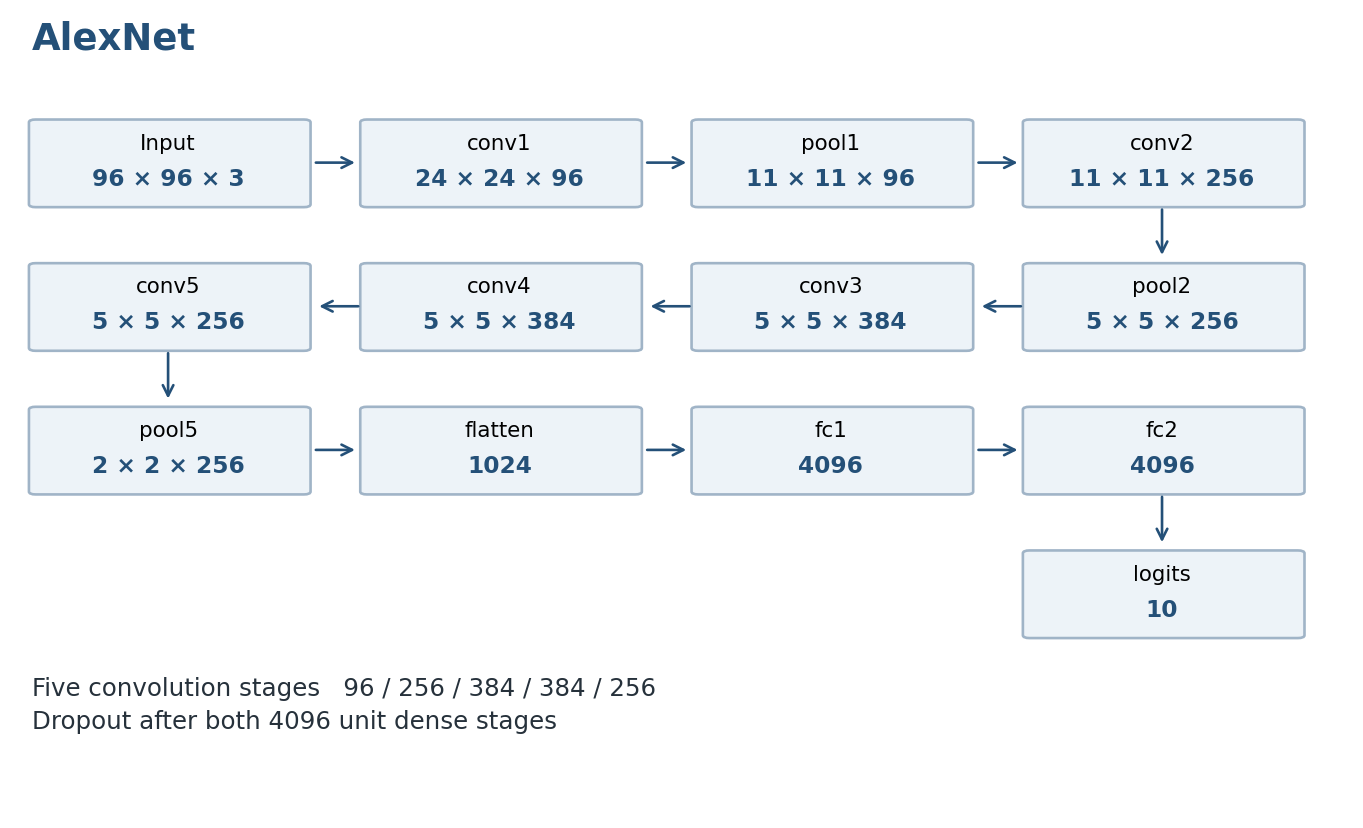

Model: "VGG16_96"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                                        ┃ Output Shape            
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━
│ raw_pixels (InputLayer)                             │ (None, 96, 96, 3)       
├─────────────────────────────────────────────────────┼─────────────────────────
│ scale_01 (Rescaling)                                │ (None, 96, 96, 3)       
├─────────────────────────────────────────────────────┼─────────────────────────
│ block1_conv1 (Conv2D)                               │ (None, 96, 96, 64)      
├─────────────────────────────────────────────────────┼─────────────────────────
│ block1_conv2 (Conv2D)                               │ (None, 96, 96, 64)      
├─────────────────────────────────────────────────────┼─────────────────────────
│ block1_pool (MaxPooling2D)                          │ (None, 48, 48, 64)      
├─────────

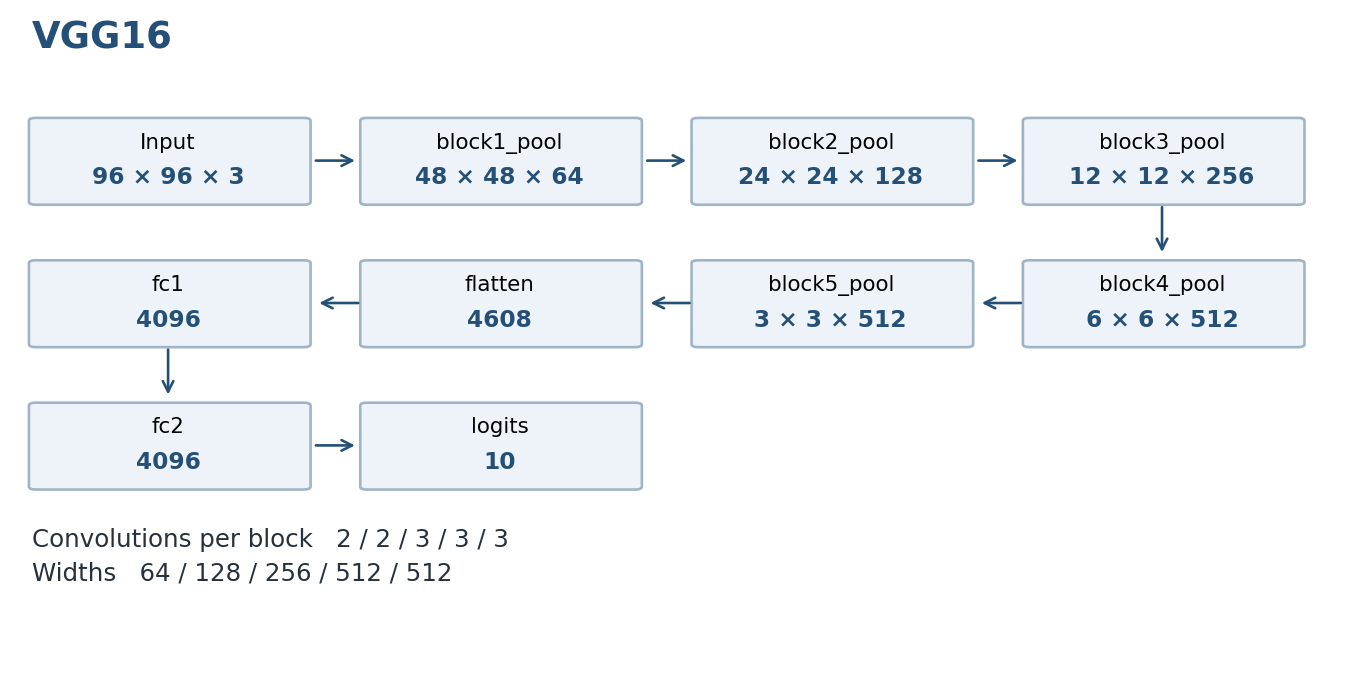

Model: "GoogLeNet96"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━
┃ Layer (type)                      ┃ Output Shape                  ┃           
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━
│ raw_pixels (InputLayer)           │ (None, 96, 96, 3)             │           
├───────────────────────────────────┼───────────────────────────────┼───────────
│ scale_01 (Rescaling)              │ (None, 96, 96, 3)             │           
├───────────────────────────────────┼───────────────────────────────┼───────────
│ stem_conv7 (Conv2D)               │ (None, 48, 48, 64)            │           
├───────────────────────────────────┼───────────────────────────────┼───────────
│ stem_pool1 (MaxPooling2D)         │ (None, 24, 24, 64)            │           
├───────────────────────────────────┼───────────────────────────────┼───────────
│ stem_reduce (Conv2D)              │ (None, 24, 24, 64)            │           
├──────

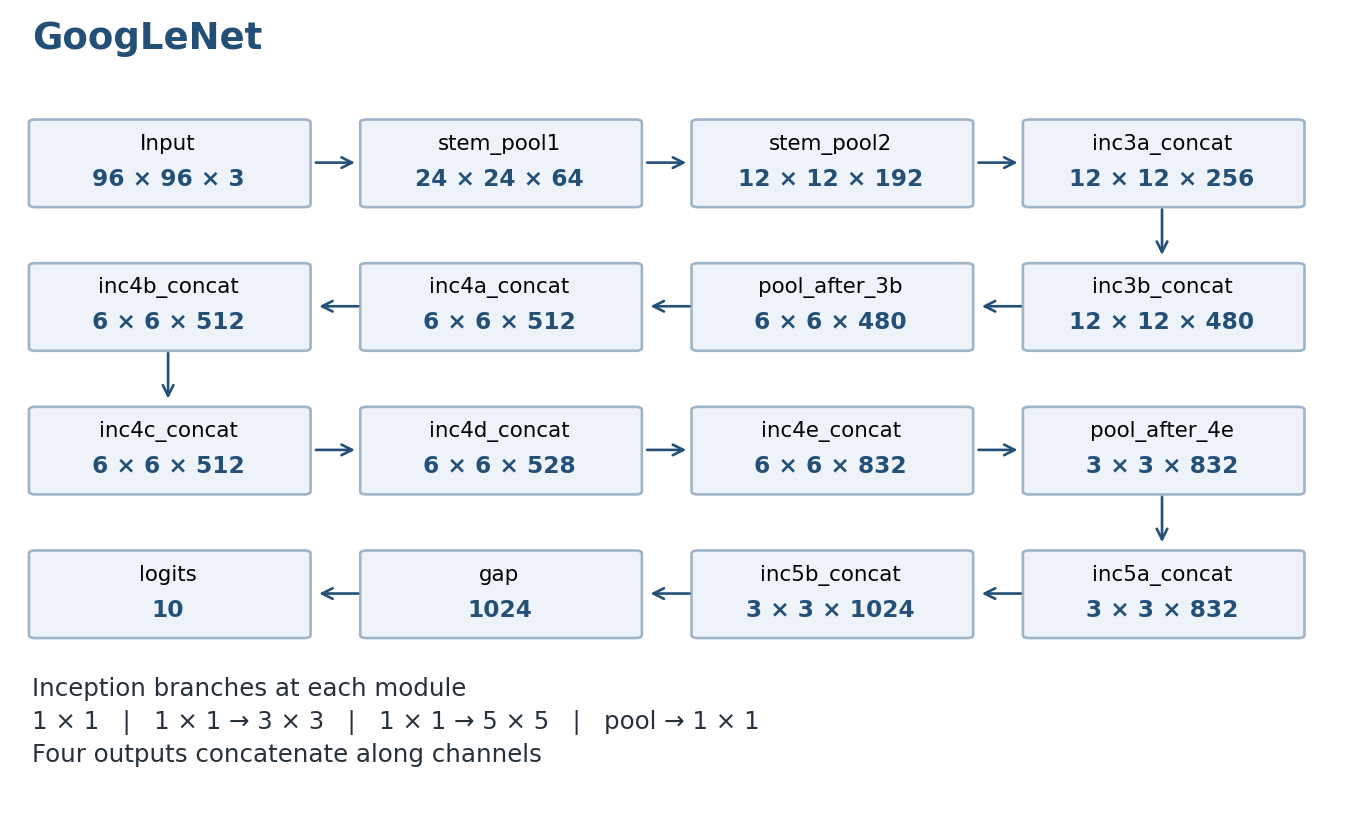

Model: "ResNet18_96"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━
┃ Layer (type)                      ┃ Output Shape                  ┃           
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━
│ raw_pixels (InputLayer)           │ (None, 96, 96, 3)             │           
├───────────────────────────────────┼───────────────────────────────┼───────────
│ scale_01 (Rescaling)              │ (None, 96, 96, 3)             │           
├───────────────────────────────────┼───────────────────────────────┼───────────
│ stem_conv (Conv2D)                │ (None, 48, 48, 64)            │           
├───────────────────────────────────┼───────────────────────────────┼───────────
│ stem_bn (BatchNormalization)      │ (None, 48, 48, 64)            │           
├───────────────────────────────────┼───────────────────────────────┼───────────
│ stem_relu (ReLU)                  │ (None, 48, 48, 64)            │           
├──────

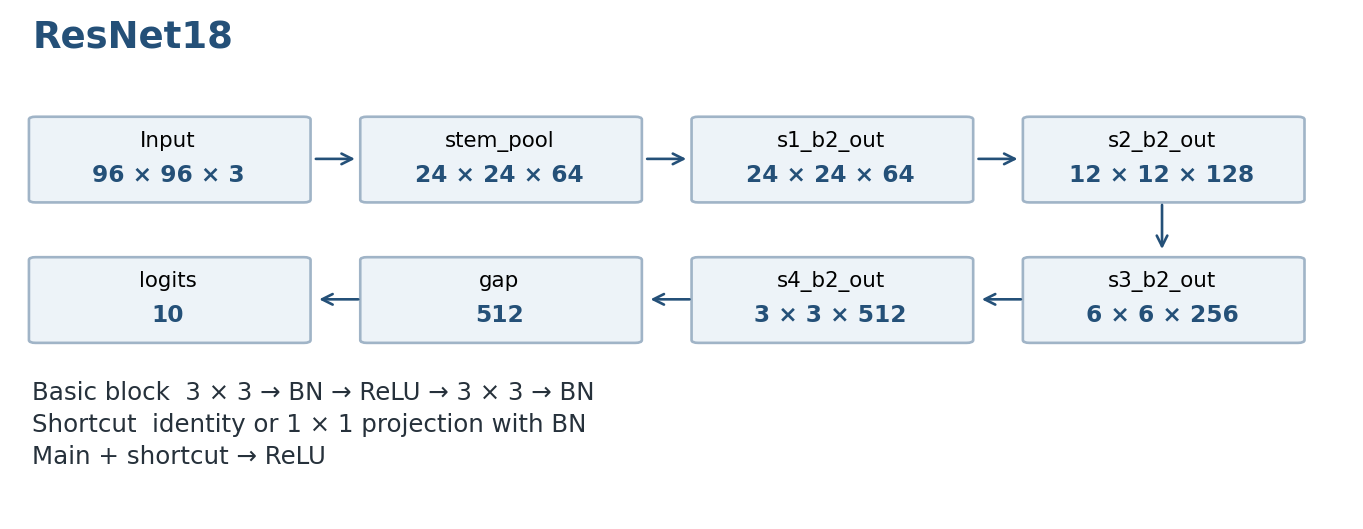

In [8]:
import json
from IPython.display import display, Image

run_module('src.reasoning')
run_module('src.checks')
run_module('src.figures')
for name in ('AlexNet', 'VGG16', 'GoogLeNet', 'ResNet18'):
    print((Path('evidence') / f'{name}_summary.txt').read_text(encoding='utf8'))
    display(Image(filename=f'figures/{name}.png', width=700))

## 2 Train and validate on the T4

I use 96 × 96 images for AlexNet, VGG16, GoogLeNet and ResNet18, and 64 × 64 images for the scratch ablations. The transfer runs also use 96 × 96 images and the ResNet50 preprocessing. If two epochs have the same validation accuracy, I keep the earlier checkpoint.

To resume training, use the same Colab session and settings. The notebook skips finished runs and logs failed attempts. Use a new results folder if you change the batch size or precision.

In [10]:
EXPERIMENT = 'experiment'
BATCH = 32
TRANSFER_BATCH = 32
PRECISION = 'mixed_float16'
OPTIONS = ('--output', EXPERIMENT, '--batch', BATCH, '--transfer-batch', TRANSFER_BATCH, '--precision', PRECISION)

# A compiled pass can recover a saved checkpoint when eager validation differs.
Path('recheck_validation.py').write_text("\"\"\"Replay validation for an already fitted checkpoint without retraining.\"\"\"\nimport hashlib\nimport json\nfrom pathlib import Path\nfrom datetime import datetime, timezone\nimport keras\nimport numpy as np\nfrom sklearn.metrics import accuracy_score, f1_score\nimport tensorflow as tf\nfrom src.experiment import (SCRATCH_ABLATIONS, build, compile_for, completed,\n    load_development, pipeline, prepare, read_json, write_json)\n\nimport sys\nroot = Path(sys.argv[1] if len(sys.argv) > 1 else 'experiment').resolve()\nenv = read_json(root/'environment.json')\nassert not env['protocol']['smoke']\nassert (tf.__version__, keras.__version__) == (env['tensorflow'], env['keras'])\nfor file in Path('src').glob('*.py'):\n    digest = hashlib.sha256(file.read_text(encoding='utf-8-sig').encode('utf8')).hexdigest()\n    assert digest == env['source_sha256'][file.name], file\nfor gpu in tf.config.list_physical_devices('GPU'):\n    tf.config.experimental.set_memory_growth(gpu, True)\ntf.config.experimental.enable_op_determinism()\ndev = load_development(root, False)\ny = dev[1][1]\nassert len(y) == 3000\nprior = completed(root)\nerror = 'Restored checkpoint validation accuracy disagrees with its history.'\nfor path in sorted((root/'runs').glob('*/attempt_*/record.json')):\n    row = read_json(path)\n    if row['status'] != 'failed' or error not in row.get('error','') or row['run_id'] in prior:\n        continue\n    original = path.parent\n    weights = original/'best.weights.h5'\n    history = read_json(original/'history.json')\n    best = int(np.argmax(history['val_accuracy']))\n    assert weights.is_file() and len(history['val_accuracy']) == 5\n    variant = row['architecture_or_variant']\n    prepare(row['seed'],row['precision'])\n    model = build(variant,row['seed'],root,restore=True)\n    compile_for(model,row['learning_rate'])\n    model.load_weights(weights)\n    val = pipeline(dev[1],64 if variant in SCRATCH_ABLATIONS else 96,row['batch'])\n    logits = model.predict(val, verbose=0)\n    assert logits.shape == (len(y),10) and np.isfinite(logits).all()\n    pred = np.argmax(logits,axis=1)\n    fresh = float(accuracy_score(y,pred))\n    logged = float(history['val_accuracy'][best])\n    replay_correct = int(np.sum(y == pred))\n    fit_correct = round(logged * len(y))\n    detail = dict(run_id=row['run_id'],replay_utc=datetime.now(timezone.utc).isoformat(),\n        first_attempt=row['attempt'],best_epoch=best+1,fit_val_accuracy=logged,\n        replay_val_accuracy=fresh,fit_correct=fit_correct,replay_correct=replay_correct,\n        examples=len(y),basis='Original best weights, compiled Keras predict')\n    write_json(original/'validation_replay.json',detail)\n    if abs(replay_correct-fit_correct)>3:\n        raise RuntimeError(f'Checkpoint difference exceeded 3 of 3000 predictions: {detail}')\n    sub = original.parent\n    seq = max(int(x.name.split('_')[1]) for x in sub.glob('attempt_*'))+1\n    dest = sub/f'attempt_{seq:02d}'\n    dest.mkdir()\n    row.update(status='completed',attempt=seq,error='',checkpoint=weights.relative_to(root).as_posix(),\n        epochs=len(history['loss']),best_epoch=best+1,best_val_accuracy=fresh,\n        macro_f1=float(f1_score(y,pred,labels=range(10),average='macro',zero_division=0)),\n        final_train_accuracy=history['accuracy'][-1],final_val_accuracy=history['val_accuracy'][-1],\n        generalization_gap=history['accuracy'][-1]-history['val_accuracy'][-1],\n        caveat=row['caveat']+'. Compiled validation replay of the original checkpoint. Fit time is from the original fit.')\n    write_json(dest/'record.json',row)\n    write_json(dest/'validation_replay.json',detail)\n    prior = completed(root)\n    print(json.dumps(detail),flush=True)\n    del model\n    keras.backend.clear_session()\n", encoding='utf8')

PHASE_RUNS = {
    'scratch': ('AlexNet', 'VGG16', 'GoogLeNet', 'ResNet18', 'A0', 'A1', 'A2', 'A3-P', 'A3-R'),
    'transfer': ('A4-F', 'A4-T'),
    'repeat': ('A0', 'A1', 'A2', 'A3-P', 'A3-R'),
}

def completed_runs():
    path = Path(EXPERIMENT, 'results.json')
    if not path.is_file():
        return set()
    return {r['run_id'] for r in json.loads(path.read_text()) if r['status'] == 'completed'}

def train_and_replay(phase):
    args = [sys.executable, '-u', '-m', 'src.experiment', '--phase', phase, *map(str, OPTIONS)]
    if subprocess.run(args).returncode:
        subprocess.run([sys.executable, '-u', 'recheck_validation.py', EXPERIMENT], check=True)

def run_phase(phase):
    seed = 123 if phase == 'repeat' else 42
    expected = {f'{name}_s{seed}' for name in PHASE_RUNS[phase]}
    if expected - completed_runs():
        train_and_replay(phase)
    missing = expected - completed_runs()
    if phase == 'transfer' and missing == {'A4-T_s42'}:
        train_and_replay(phase)
        missing = expected - completed_runs()
    if missing:
        raise RuntimeError(f'Check the saved attempt records for {sorted(missing)}')
    print(f'{phase}: {len(expected)} completed runs')

run_phase('scratch')

scratch: 9 completed runs


In [11]:
run_phase('transfer')

transfer: 2 completed runs


In [12]:
REPEAT_SEED_123 = True
if REPEAT_SEED_123:
    run_phase('repeat')

repeat: 5 completed runs


## 3 Select a checkpoint and test it

I compare the required seed 42 runs by validation accuracy. If two runs tie, I use validation macro F1 and then the run ID. I save the choice before testing that checkpoint on the original test set. On a repeat call, the saved selection prevents a second evaluation.

In [13]:
run_module('src.experiment', '--phase', 'test', *OPTIONS)
print((Path(EXPERIMENT) / 'test_metrics.json').read_text(encoding='utf8'))

{
  "run_id": "A4-T_s42",
  "count": 10000,
  "accuracy": 0.8423,
  "macro_f1": 0.8421974526945138,
  "labels": [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
  ],
  "confusion_matrix": [
    [
      826,
      13,
      38,
      10,
      18,
      1,
      6,
      9,
      58,
      21
    ],
    [
      13,
      893,
      0,
      1,
      1,
      0,
      2,
      3,
      15,
      72
    ],
    [
      21,
      1,
      836,
      38,
      43,
      13,
      33,
      6,
      6,
      3
    ],
    [
      9,
      3,
      41,
      733,
      36,
      102,
      40,
      21,
      8,
      7
    ],
    [
      8,
      2,
      56,
      23,
      817,
      11,
      38,
      35,
      7,
      3
    ],
    [
      3,
      0,
      13,
      133,
      27,
      777,
      17,
      29,
      1,
      0
    ],
    [
      6,
      4,
      22,
      47,
      21,
      9,
      882,

## 4 Review the results

I compare the learning curves and the ablation scores. The confusion matrix shows which classes the selected model mixed up. The experiment folder contains the results CSV, the JSON records and the logs for each run.

11 required runs and 5 optional runs completed.
Winner A4-T_s42 | validation accuracy 85.13% | test accuracy 84.23% | test macro F1 84.22%
Results CSV: experiment/results.csv


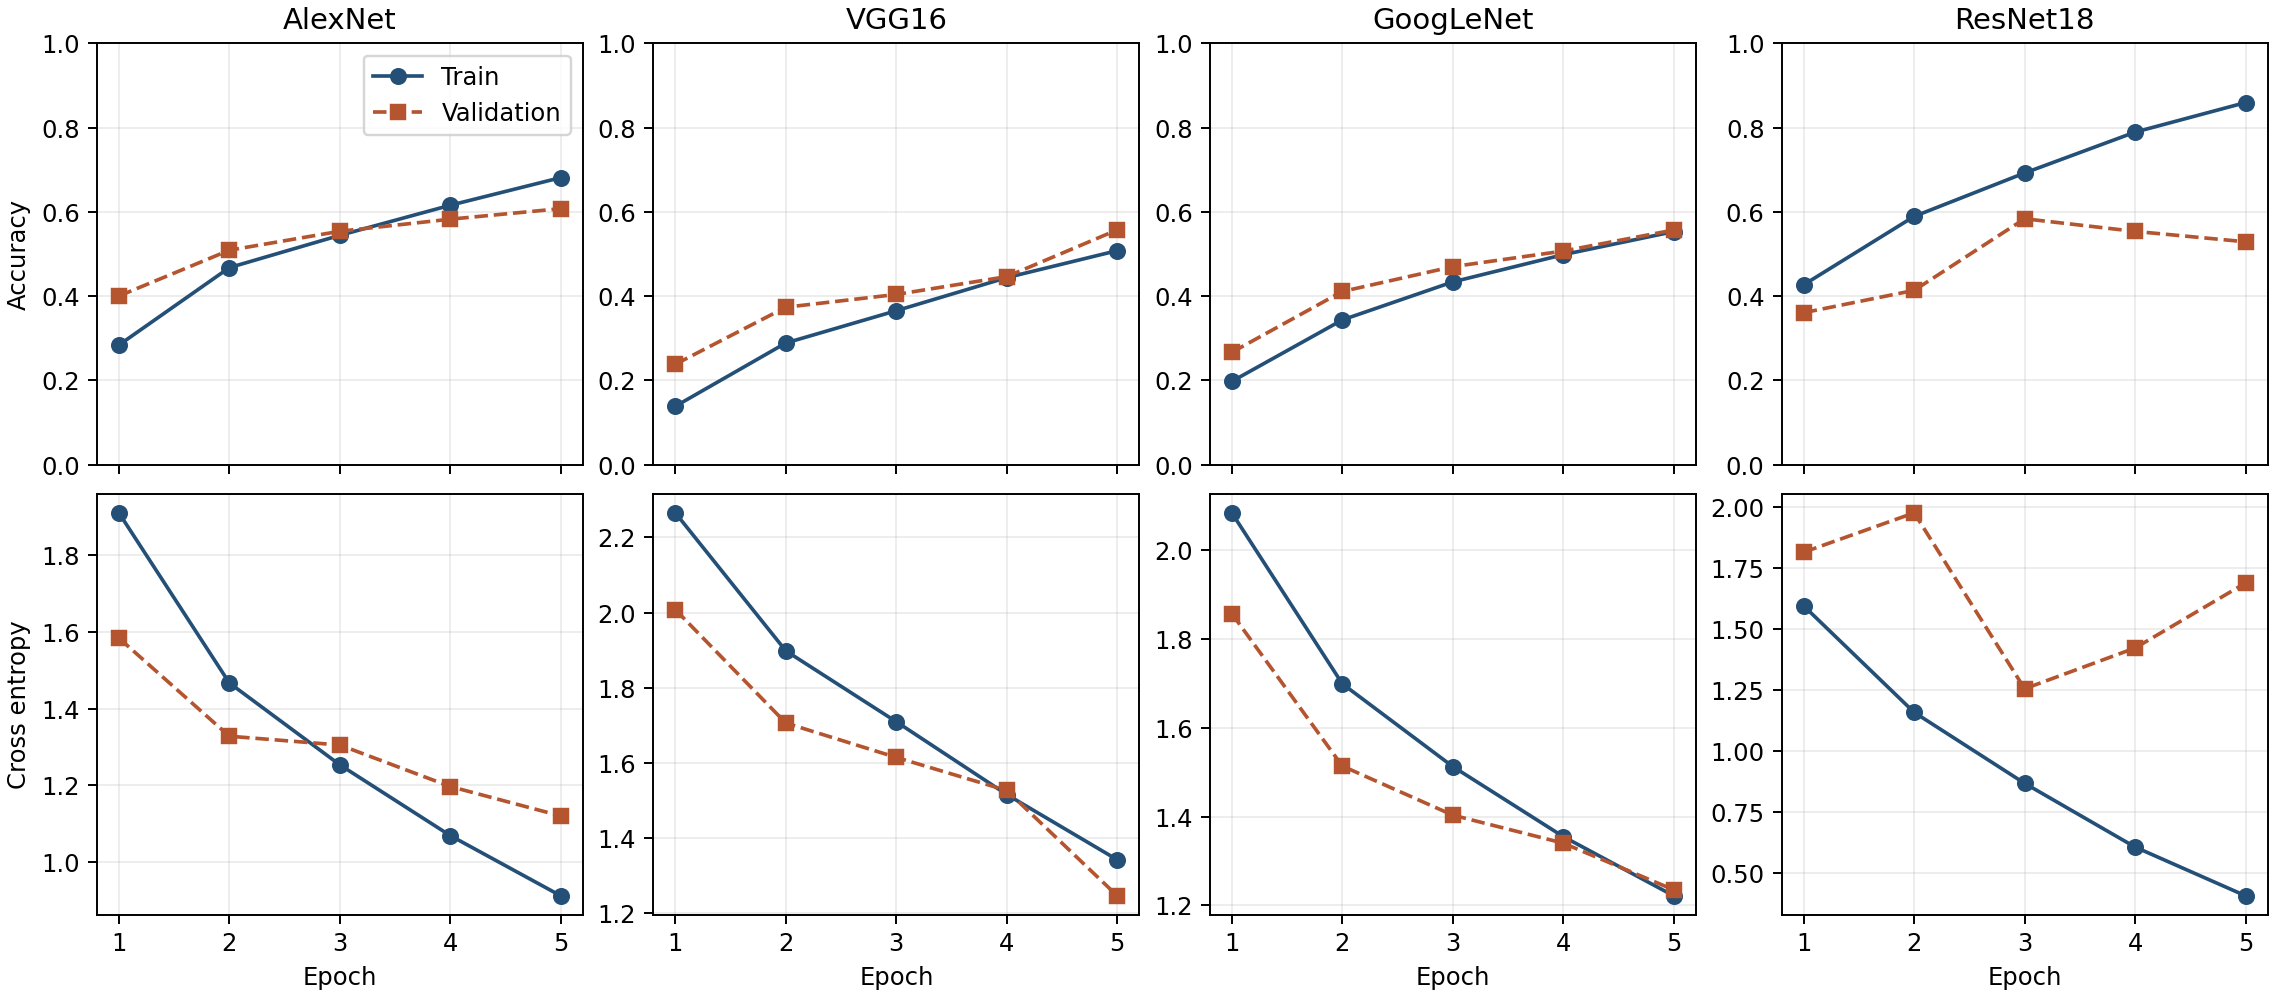

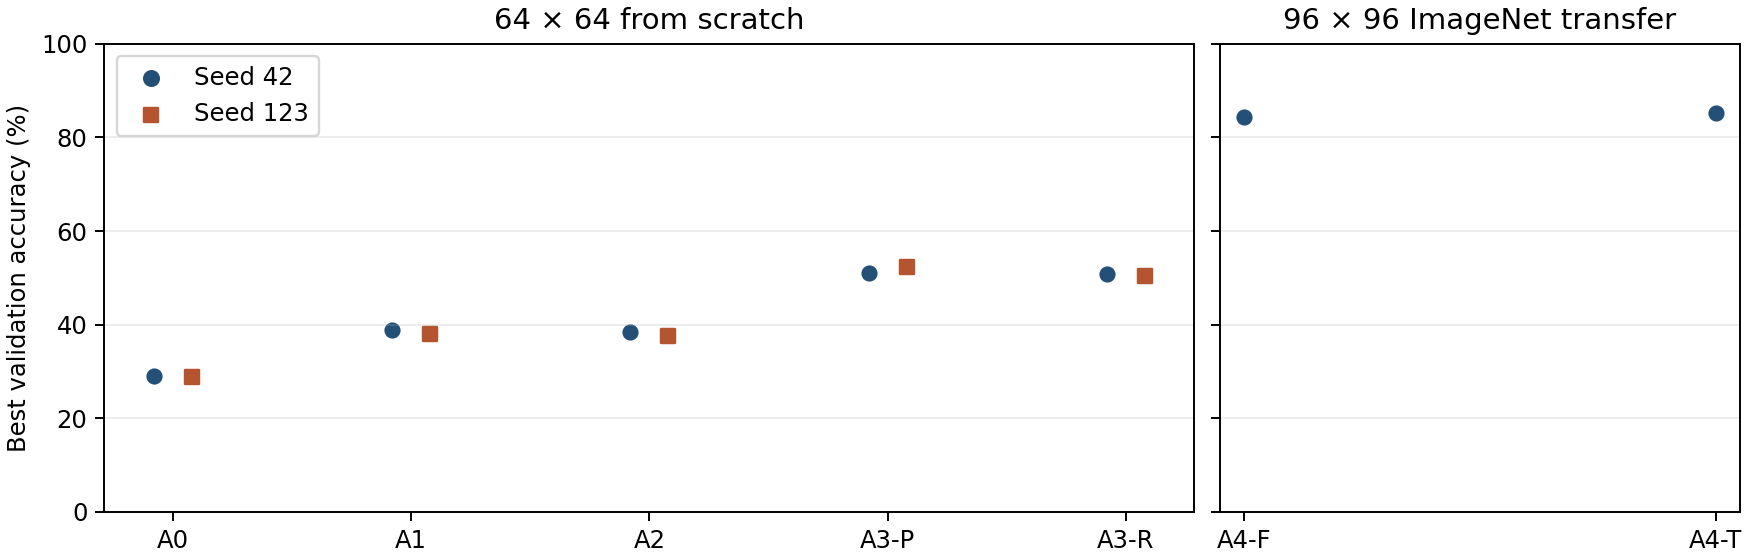

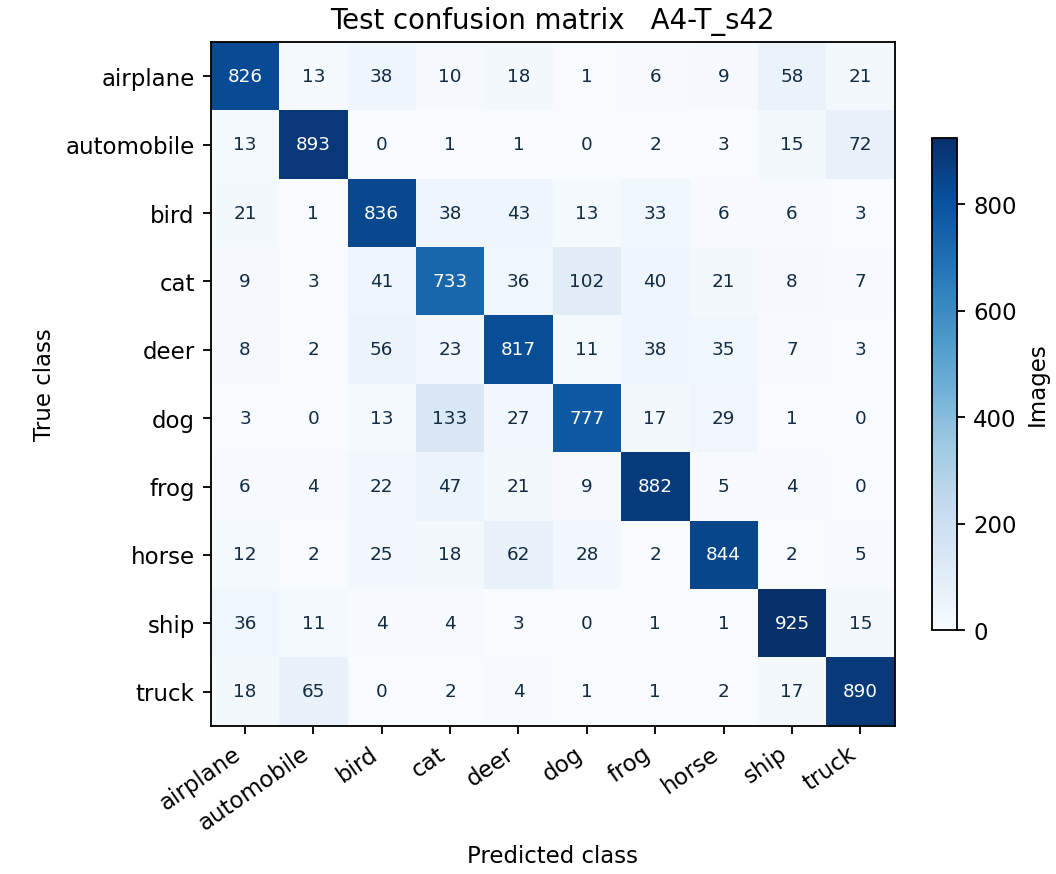

In [17]:
run_module('src.figures', '--results', EXPERIMENT)

results_dir = Path(EXPERIMENT)
rows = json.loads((results_dir / 'results.json').read_text())
selection = json.loads((results_dir / 'selection.json').read_text())
test = json.loads((results_dir / 'test_metrics.json').read_text())
completed = [row for row in rows if row['status'] == 'completed']

print(f"{sum(row['seed'] == 42 for row in completed)} required runs and "
      f"{sum(row['seed'] == 123 for row in completed)} optional runs completed.")
print(f"Winner {test['run_id']} | validation accuracy {selection['winner']['best_val_accuracy']:.2%} | "
      f"test accuracy {test['accuracy']:.2%} | test macro F1 {test['macro_f1']:.2%}")
print(f"Results CSV: {results_dir / 'results.csv'}")

for name in ('architecture_curves', 'ablation_accuracy', 'confusion_matrix'):
    display(Image(filename=f'figures/{name}.png', width=750))